In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from scipy.stats import skew
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import (
    LinearRegression, Ridge, Lasso, ElasticNet, RidgeCV, LassoCV, ElasticNetCV
)
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score, KFold
%matplotlib inline

In [3]:
# خواندن فایل csv
df= pd.read_csv('used_cars.csv')

In [ ]:
# بررسی کلی فایل خوانده شده
df.head(10)
# df.tail()
df.columns
# df.index
# df.attrs
# df.value_counts()
# df.values
# df.dtypes
# df.shape
# df.empty

In [ ]:
df.info()

In [ ]:
#  آمار توصیفی برای ستون‌های عددی
df.describe()

In [ ]:
#  آمار توصیفی برای ستون‌های دسته‌ای
df.describe(exclude=[np.number])

In [ ]:
df.nunique()

In [4]:
# تشخیص و پردازش رکوردهای تکراری
dr= df.duplicated()
print(dr.sum())

1202


In [5]:
df = df.drop_duplicates().reset_index(drop=True)
print("Shape:", df.shape)

Shape: (6926, 13)


In [6]:
# تشخیص و شناسایی مقادیر خالی و اعمال استراتژی مناسب
print(df.isnull().sum())


name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          208
engine           208
max_power        205
torque           209
seats            208
dtype: int64


In [7]:
# مقادیر خالی در برخی ستونها وجود دارد. با توجه به فرمت اشتباه برخی ستونها اول باید این مشکل را حل کنیم
text_cols = ["mileage", "engine", "max_power", "torque"]
for col in text_cols:
    s = df[col]
    print(f"{col:12s} | NaN: {s.isna().sum():3d} | خالی: {(s.astype(str).str.strip()=='').sum():3d} | 'nan': {(s.astype(str).str.lower()=='nan').sum():3d}")

mileage      | NaN: 208 | خالی:   0 | 'nan': 208
engine       | NaN: 208 | خالی:   0 | 'nan': 208
max_power    | NaN: 205 | خالی:   0 | 'nan': 205
torque       | NaN: 209 | خالی:   0 | 'nan': 209


In [8]:
# بررسی اینکه آیا مقادیر غیرمنتظره (غیر از الگوی عدد+واحد) داریم
for col in ["mileage", "engine", "max_power", "torque"]:
    vals = df[col].dropna().astype(str)
    # اونایی که با عدد شروع نمی‌شن
    bad = vals[~vals.str.match(r"^\s*\d")]
    print(f"\n{col}: {len(bad)} مقدار غیرعادی")
    if len(bad) > 0:
        print(bad.head(10).tolist())


mileage: 0 مقدار غیرعادی

engine: 0 مقدار غیرعادی

max_power: 1 مقدار غیرعادی
[' bhp']

torque: 0 مقدار غیرعادی


In [9]:
# ----------  یکسان‌سازی مقادیر خالی" ----------
text_cols = ["mileage", "engine", "max_power", "torque"]
for col in text_cols:
    df[col] = df[col].replace(r"^\s*$", np.nan, regex=True)  # رشته خالی/فاصله
    df[col] = df[col].replace(r"^\s*bhp\s*$", np.nan, regex=True)  # " bhp" بدون عدد
    df[col] = df[col].replace("nan", np.nan)
    df[col] = df[col].replace("None", np.nan)
    df[col] = df[col].replace("-", np.nan)

In [10]:
# تبدیل ستون mileage به داده عددی ---- mileage: "23.4 kmpl" → 23.4
df["mileage"] = df["mileage"].astype(str).str.extract(r"([\d.]+)")[0].astype(float)
# تبدیل ستون engine به عددی-----------engine: "1248 CC" → 1248
df["engine"] = df["engine"].astype(str).str.extract(r"([\d.]+)")[0].astype(float)
# تبدیل ستون max_power به عددی----------------max_power: "74 bhp" → 74
df["max_power"] = df["max_power"].replace("", np.nan)
df["max_power"] = df["max_power"].astype(str).str.extract(r"([\d.]+)")[0].astype(float)
# تبدیل ستون torque به عددی
def clean_torque(x):
    """
    استخراج گشتاور به Nm.
    فرمت‌های ممکن:
      "190Nm@ 2000rpm"
      "250Nm@ 1500-2500rpm"
      "22.4 kgm at 1750-2750rpm"
      "12.7@ 2,700(kgm@ rpm)"
      "200@ 3000rpm"
      "380Nm(38.7kgm)@ 2500rpm"  
    """
    if pd.isna(x):
        return np.nan
    s = str(x).lower().replace(",", "").strip()
    #  اولین عدد و واحدی که بلافاصله بعدش میاد 
    m = re.search(r"(\d+\.?\d*)\s*(nm|kgm)?", s)
    if not m:
        return np.nan
    val = float(m.group(1))
    unit = m.group(2)   # None اگر واحد نبود
    #  تبدیل بر اساس واحد 
    if unit == "kgm":
        val = val * 9.81
    elif unit == "nm":
        pass  # همون عدد
    else:
        # واحد صریح نداشت → حدس بر اساس بازه منطقی
        # گشتاور خودرو سواری معمولاً ۵۰ تا ۵۰۰ Nm
        if val < 50:
            val = val * 9.81   # احتمالاً kgm بوده
    return round(val, 2)

df["torque"] = df["torque"].apply(clean_torque)
# تبدیل ستون seats به عددی
df["seats"] = pd.to_numeric(df["seats"], errors="coerce")

In [11]:
print(df.dtypes)
print("\n=== مقادیر خالی ===")
print(df.isnull().sum())
print("\n=== آمار توصیفی ===")
print(df[["mileage", "engine", "max_power", "torque", "seats"]].describe())

name              object
year               int64
selling_price      int64
km_driven          int64
fuel              object
seller_type       object
transmission      object
owner             object
mileage          float64
engine           float64
max_power        float64
torque           float64
seats            float64
dtype: object

=== مقادیر خالی ===
name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          208
engine           208
max_power        206
torque           209
seats            208
dtype: int64

=== آمار توصیفی ===
          mileage       engine    max_power       torque        seats
count  6718.00000  6718.000000  6720.000000  6717.000000  6718.000000
mean     19.46531  1430.891337    87.726919   170.947792     5.434653
std       4.04915   493.493277    31.771619    84.539610     0.984230
min       0.00000   624.000000     0.000000    47.090

In [12]:
# حل مقادیر nan
 # استخراج برند 
df["brand"] = df["name"].str.split().str[0]
# بررسی برندها
# print("تعداد برندهای یکتا:", df["brand"].nunique())
# print(df["brand"].value_counts().head(15))
#  اول مقادیر "NaN پنهان" رو NaN واقعی کنیم
df.loc[df["max_power"] == 0, "max_power"] = np.nan
df.loc[df["mileage"] == 0, "mileage"] = np.nan

# ----------  پر کردن با میانه برند ----------
cols_to_fill = ["mileage", "engine", "max_power", "torque", "seats"]
for col in cols_to_fill:
    n_before = df[col].isna().sum()
    # میانه گروهی بر اساس برند
    brand_median = df.groupby("brand")[col].transform("median")
    df[col] = df[col].fillna(brand_median)
    # : اگر برندی همه NaN بود → میانه کلی
    df[col] = df[col].fillna(df[col].median())
    n_after = df[col].isna().sum()
    print(f"{col:12s} | NaN قبل: {n_before:3d} → بعد: {n_after}")
#  چک نهایی
print("NaN باقی‌مانده:")
print(df.isnull().sum())


mileage      | NaN قبل: 223 → بعد: 0
engine       | NaN قبل: 208 → بعد: 0
max_power    | NaN قبل: 209 → بعد: 0
torque       | NaN قبل: 209 → بعد: 0
seats        | NaN قبل: 208 → بعد: 0
NaN باقی‌مانده:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
mileage          0
engine           0
max_power        0
torque           0
seats            0
brand            0
dtype: int64


In [13]:
   # استفاده از روش iqr برای تشخیص داده های پرت
def outlier_summary(df, col):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    n_out = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f"{col:12s} | Q1={Q1:8.2f} | Q3={Q3:8.2f} | IQR={IQR:7.2f} | "
          f"lower={lower:8.2f} | upper={upper:9.2f} | outliers={n_out:4d} "
          f"({n_out/len(df)*100:.1f}%)")

num_cols = ["selling_price", "km_driven", "mileage", "engine",
            "max_power", "torque", "seats", "year"]

print("=== خلاصه outlier با روش IQR ===\n")
for col in num_cols:
    outlier_summary(df, col)

=== خلاصه outlier با روش IQR ===

selling_price | Q1=250000.00 | Q3=633500.00 | IQR=383500.00 | lower=-325250.00 | upper=1208750.00 | outliers= 328 (4.7%)
km_driven    | Q1=40000.00 | Q3=100000.00 | IQR=60000.00 | lower=-50000.00 | upper=190000.00 | outliers= 167 (2.4%)
mileage      | Q1=   16.80 | Q3=   22.32 | IQR=   5.52 | lower=    8.52 | upper=    30.60 | outliers=   6 (0.1%)
engine       | Q1= 1197.00 | Q3= 1498.00 | IQR= 301.00 | lower=  745.50 | upper=  1949.50 | outliers=1256 (18.1%)
max_power    | Q1=   68.00 | Q3=  100.00 | IQR=  32.00 | lower=   20.00 | upper=   148.00 | outliers= 307 (4.4%)
torque       | Q1=  111.80 | Q3=  200.12 | IQR=  88.32 | lower=  -20.68 | upper=   332.60 | outliers= 288 (4.2%)
seats        | Q1=    5.00 | Q3=    5.00 | IQR=   0.00 | lower=    5.00 | upper=     5.00 | outliers=1511 (21.8%)
year         | Q1= 2011.00 | Q3= 2017.00 | IQR=   6.00 | lower= 2002.00 | upper=  2026.00 | outliers=  77 (1.1%)


In [14]:
print("\n=== توزیع seats ===")
print(df["seats"].value_counts().sort_index())
# خودروهای با 2 و 14 سرنشین را از نظر صحت بررسی می کنیم
print(df[df["seats"].isin([2,14])][["name", "seats", "selling_price"]].head(20).to_string())
# با بررسی در اینترنت معلوم شد 2 صندلی ها وانت و 14 صندلی ون بوده و اطلاعات صحیح بوده و پرت نیست


=== توزیع seats ===
seats
2.0        2
4.0      124
5.0     5415
6.0       57
7.0     1013
8.0      222
9.0       74
10.0      18
14.0       1
Name: count, dtype: int64
                                         name  seats  selling_price
3972  Tata Winger Deluxe - Flat Roof (Non-AC)   14.0         235000
5125           Mahindra Bolero Pik-Up FB 1.7T    2.0         679000
5701          Mahindra Bolero Pik-Up CBC 1.7T    2.0         722000


In [15]:
print("\n=== torque > 800 (مشکوک) ===")
print(df[df["torque"] > 800][["name", "engine", "max_power", "torque"]].sort_values("torque", ascending=False).to_string())


=== torque > 800 (مشکوک) ===
Empty DataFrame
Columns: [name, engine, max_power, torque]
Index: []


In [16]:
print("\n=== ۱۰ خودرو با بیشترین کارکرد ===")
print(df.nlargest(10, "km_driven")[["name", "year", "km_driven", "selling_price"]].to_string())
# با توجه به خروجی 2 خودزو بالای یک میلیون مسافت طی شده داریم که با توجه به نوع خودروها منطقی نیست


=== ۱۰ خودرو با بیشترین کارکرد ===
                                               name  year  km_driven  selling_price
3161                           Hyundai i20 Asta 1.2  2007    2360457         550000
1646                         Mahindra XUV500 W6 2WD  2012    1500000         500000
3183                       Maruti Wagon R LXI Minor  2010     577414         194000
3284                       Maruti Wagon R VXI BS IV  2011     500000         229999
5744  Toyota Innova 2.5 EV Diesel PS 7 Seater BSIII  2011     500000         350000
4411                          Mahindra Scorpio M2DI  2011     475000         400000
4485         Toyota Innova 2.5 VX (Diesel) 7 Seater  2013     440000         750000
4737   Toyota Innova 2.5 VX (Diesel) 7 Seater BS IV  2010     426000         950000
2080                            Mahindra Bolero SLE  2010     380000         260000
6104            Toyota Innova 2.5 V Diesel 8-seater  2007     376412         350000


In [17]:
# km_driven خیلی کم (کمتر از 1000)
print("=== km_driven < 1000 ===")
print(df[df["km_driven"] < 1000][["name", "year", "km_driven", "selling_price"]].sort_values("km_driven").head(20).to_string())

print(f"\nتعداد کل: {(df['km_driven'] < 1000).sum()}")
# با توجه به سال تولید خودرو مسافت طی شده یک کیلومتر منطقی نیست

=== km_driven < 1000 ===
                                        name  year  km_driven  selling_price
6737  Maruti Eeco 5 STR With AC Plus HTR CNG  2011          1         209000

تعداد کل: 1


In [18]:
# ---------- km_driven غیرمنطقی  → NaN ----------
n_km = (df["km_driven"] > 1_000_000).sum()
df.loc[df["km_driven"] > 1_000_000, "km_driven"] = np.nan
df.loc[df["km_driven"] < 1_000, "km_driven"] = np.nan
print(f"\nkm_driven > 1M → NaN: {n_km} ردیف")

# پر کردن با میانه گروهی برند 
brand_median_km = df.groupby("brand")["km_driven"].transform("median")
df["km_driven"] = df["km_driven"].fillna(brand_median_km)
df["km_driven"] = df["km_driven"].fillna(df["km_driven"].median())
print(f"NaN باقی‌مانده km_driven: {df['km_driven'].isna().sum()}")


km_driven > 1M → NaN: 2 ردیف
NaN باقی‌مانده km_driven: 0


In [19]:
print("\n=== mileage < 10 (خیلی کم‌مصرف) ===")
print(df[df["mileage"] < 10][["name", "fuel", "mileage"]].head(10).to_string())

print("\n=== mileage > 35 (خیلی پرمصرف) ===")
print(df[df["mileage"] > 35][["name", "fuel", "mileage"]].head(10).to_string())
# با توجه به بررسی خروجی، داده ها را نگه می داریم


=== mileage < 10 (خیلی کم‌مصرف) ===
                                 name    fuel  mileage
134   Jeep Wrangler 2016-2019 3.6 4X4  Petrol      9.5
599                Honda Accord V6 AT  Petrol      9.0
1942               Honda Accord V6 AT  Petrol      9.0
2603              Volvo S60 D4 SUMMUM  Diesel      9.0
4344              Volvo S60 D4 SUMMUM  Diesel      9.0

=== mileage > 35 (خیلی پرمصرف) ===
                              name    fuel  mileage
170  Volvo XC90 T8 Excellence BSIV  Petrol     42.0


In [20]:
print("\n=== max_power > 300 ===")
print(df[df["max_power"] > 300][["name", "engine", "max_power"]].head(10).to_string())
# با توجه به بررسی خروجی، داده ها را نگه می داریم


=== max_power > 300 ===
                              name  engine  max_power
170  Volvo XC90 T8 Excellence BSIV  1969.0      400.0


In [21]:
# تولید ستون سن خودرو از روی سال تولید
CURRENT_YEAR = 2026  
df["car_age"] = CURRENT_YEAR - df["year"]

print("بازه car_age:", df["car_age"].min(), "تا", df["car_age"].max())
print(df["car_age"].describe())

بازه car_age: 6 تا 43
count    6926.000000
mean       12.579700
std         4.078286
min         6.000000
25%         9.000000
50%        12.000000
75%        15.000000
max        43.000000
Name: car_age, dtype: float64


In [22]:
# تولید ویژگی کارکرد سالانه
df["km_per_year"] = df["km_driven"] / (df["car_age"] + 1)

print(df["km_per_year"].describe())

count     6926.000000
mean      5321.662690
std       3174.486685
min        111.111111
25%       3125.000000
50%       4991.461111
75%       6875.000000
max      33965.529412
Name: km_per_year, dtype: float64


In [23]:
# حذف name و year
df = df.drop(columns=["name", "year"])
print("ستون‌های باقی‌مانده:")
print(df.columns.tolist())
print("shape:", df.shape)

ستون‌های باقی‌مانده:
['selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage', 'engine', 'max_power', 'torque', 'seats', 'brand', 'car_age', 'km_per_year']
shape: (6926, 14)


In [24]:
# بررسی همبستگی ویژگی ها با selling_price
# فقط ستون‌های عددی
numeric_df = df.select_dtypes(include=np.number)
corr_with_target = numeric_df.corr()["selling_price"].sort_values(ascending=False)
print("=== همبستگی با selling_price ===")
print(corr_with_target)

=== همبستگی با selling_price ===
selling_price    1.000000
max_power        0.689514
torque           0.623686
engine           0.433594
seats            0.156684
km_per_year     -0.053328
mileage         -0.106823
km_driven       -0.199518
car_age         -0.433076
Name: selling_price, dtype: float64


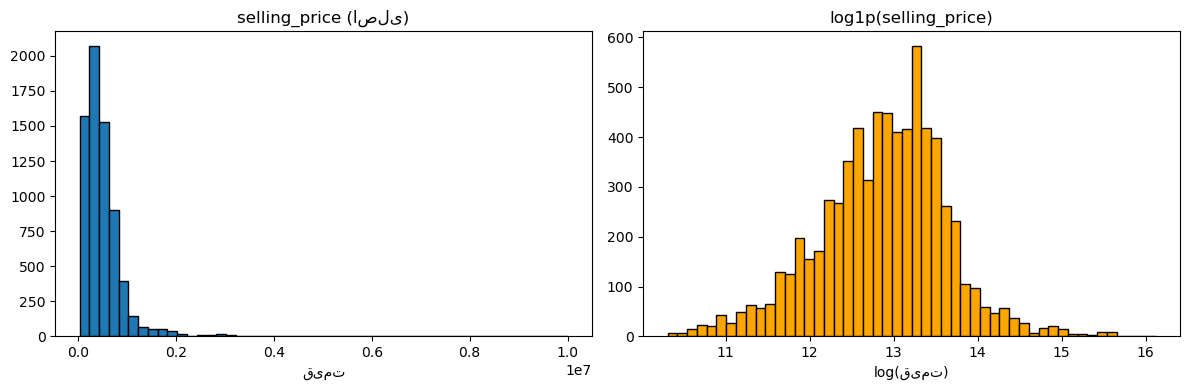

چولگی اصلی: 5.572
چولگی لگاریتمی: -0.157


In [25]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# توزیع اصلی
axes[0].hist(df["selling_price"], bins=50, edgecolor="black")
axes[0].set_title("selling_price (اصلی)")
axes[0].set_xlabel("قیمت")

# توزیع لگاریتمی
axes[1].hist(np.log1p(df["selling_price"]), bins=50, edgecolor="black", color="orange")
axes[1].set_title("log1p(selling_price)")
axes[1].set_xlabel("log(قیمت)")

plt.tight_layout()
plt.show()

# چولگی
from scipy.stats import skew
print(f"چولگی اصلی: {skew(df['selling_price']):.3f}")
print(f"چولگی لگاریتمی: {skew(np.log1p(df['selling_price'])):.3f}")

In [26]:
# بررسی چولگی سایر ستونهای عددی

num_cols = df.select_dtypes(include=np.number).columns.tolist()
# target  جدا کردن
num_cols = [c for c in num_cols if c != "selling_price"]

print("=== چولگی ستون‌های ورودی ===")
skewness = {}
for col in num_cols:
    sk = skew(df[col].dropna())
    skewness[col] = sk
    print(f"{col:14s} | چولگی: {sk:>7.2f}")

print(f"\n=== چولگی target ===")
print(f"selling_price  | چولگی: {skew(df['selling_price']):>7.2f}")

=== چولگی ستون‌های ورودی ===
km_driven      | چولگی:    1.71
mileage        | چولگی:    0.05
engine         | چولگی:    1.22
max_power      | چولگی:    1.74
torque         | چولگی:    1.37
seats          | چولگی:    1.91
car_age        | چولگی:    1.01
km_per_year    | چولگی:    1.57

=== چولگی target ===
selling_price  | چولگی:    5.57


In [27]:
# با توجه به تعدد برندها، برندهای زیر 10 نمونه را به اسم other ذخیره می کنیم
brand_counts = df["brand"].value_counts()
rare_brands = brand_counts[brand_counts < 10].index.tolist()
print("برندهای نادر ادغام در Other):", rare_brands)

df["brand"] = df["brand"].replace(rare_brands, "Other")
print("\nتعداد برندهای جدید:", df["brand"].nunique())
print(df["brand"].value_counts())

برندهای نادر ادغام در Other): ['Volvo', 'Jaguar', 'Isuzu', 'Ambassador', 'Force', 'Kia', 'Land', 'Daewoo', 'MG', 'Ashok', 'Lexus', 'Opel', 'Peugeot']

تعداد برندهای جدید: 20
brand
Maruti           2165
Hyundai          1267
Mahindra          723
Tata              647
Honda             362
Ford              361
Toyota            357
Chevrolet         216
Renault           206
Volkswagen        174
Nissan             73
Skoda              70
Datsun             57
BMW                47
Mercedes-Benz      46
Other              45
Fiat               44
Audi               33
Jeep               22
Mitsubishi         11
Name: count, dtype: int64


In [28]:

# ========== One-Hot برای اسمی‌ها ==========
nominal_cols = ["fuel", "seller_type", "transmission", "brand"]

df = pd.get_dummies(df, columns=nominal_cols, drop_first=True)
print("بعد از One-Hot اسمی‌ها:", df.shape)

# ==========  Ordinal Encoding برای owner ==========
owner_order = {
    "Test Drive Car": 0,
    "First Owner": 1,
    "Second Owner": 2,
    "Third Owner": 3,
    "Fourth & Above Owner": 4,
}
unknown = set(df["owner"].unique()) - set(owner_order.keys())
if unknown:
    print(" مقادیر ناشناخته در owner:", unknown)

df["owner"] = df["owner"].map(owner_order)
print("\nowner بعد از Ordinal:")
print(df["owner"].value_counts().sort_index())

 # ==========  چک نهایی ==========
print("\n=== dtypes ===")
print(df.dtypes.value_counts())

print("\n=== ستون‌های باقی‌مانده object ===")
obj_cols = df.select_dtypes(include="object").columns.tolist()
print(obj_cols if obj_cols else " هیچ ستون object باقی نمونده")

print("\n=== isnull ===")
print(df.isnull().sum().sum(), "مقدار خالی")

print("\n=== shape نهایی ===", df.shape)
print("\n=== ستون‌ها ===")
print(df.columns.tolist())

بعد از One-Hot اسمی‌ها: (6926, 35)

owner بعد از Ordinal:
owner
0       5
1    4242
2    1974
3     536
4     169
Name: count, dtype: int64

=== dtypes ===
bool       25
float64     7
int64       3
Name: count, dtype: int64

=== ستون‌های باقی‌مانده object ===
 هیچ ستون object باقی نمونده

=== isnull ===
0 مقدار خالی

=== shape نهایی === (6926, 35)

=== ستون‌ها ===
['selling_price', 'km_driven', 'owner', 'mileage', 'engine', 'max_power', 'torque', 'seats', 'car_age', 'km_per_year', 'fuel_Diesel', 'fuel_LPG', 'fuel_Petrol', 'seller_type_Individual', 'seller_type_Trustmark Dealer', 'transmission_Manual', 'brand_BMW', 'brand_Chevrolet', 'brand_Datsun', 'brand_Fiat', 'brand_Ford', 'brand_Honda', 'brand_Hyundai', 'brand_Jeep', 'brand_Mahindra', 'brand_Maruti', 'brand_Mercedes-Benz', 'brand_Mitsubishi', 'brand_Nissan', 'brand_Other', 'brand_Renault', 'brand_Skoda', 'brand_Tata', 'brand_Toyota', 'brand_Volkswagen']


In [29]:
# تبدیل bool به int
bool_cols = df.select_dtypes(include="bool").columns.tolist()
df[bool_cols] = df[bool_cols].astype(int)

print("dtypes بعد از تبدیل:")
print(df.dtypes.value_counts())

dtypes بعد از تبدیل:
int32      25
float64     7
int64       3
Name: count, dtype: int64


In [30]:
# ========== جدا کردن X و y ==========
X = df.drop(columns=["selling_price"]).copy()
y = df["selling_price"].copy()
print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")
# ==========  log-transform فقط روی y ==========
y_log = np.log1p(y)
# ==========  Train/Test Split ==========
X_train, X_test, y_train, y_test = train_test_split(
    X, y_log,
    test_size=0.2,
    random_state=42
)
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X shape: (6926, 34)
y shape: (6926,)
X_train: (5540, 34)
X_test : (1386, 34)
y_train: (5540,)
y_test : (1386,)


In [31]:
# ==========  استاندارد سازی  ==========
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape :", X_test_scaled.shape)

# چک: میانگین train باید ~0 و std ~1 باشه
# print(f"\nمیانگین X_train_scaled: {X_train_scaled.mean():.6f}")
# print(f"std X_train_scaled    : {X_train_scaled.std():.6f}")

# چک: test با آمار train scale شده (پس میانگینش دقیقاً 0 نیست)
# print(f"میانگین X_test_scaled : {X_test_scaled.mean():.6f}  ← نباید دقیقاً 0 باشه")
# print(f"std X_test_scaled     : {X_test_scaled.std():.6f}")

X_train_scaled shape: (5540, 34)
X_test_scaled shape : (1386, 34)


In [32]:
# تابع ارزیابی (برگرداندن به مقیاس اصلی)
def evaluate(y_true_log, y_pred_log, name):
    y_true = np.expm1(y_true_log)
    y_pred = np.expm1(y_pred_log)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"{name:28s} | MAE: {mae:>12,.0f} | RMSE: {rmse:>12,.0f} | R²: {r2:>8.4f}")
    return {"name": name, "mae": mae, "rmse": rmse, "r2": r2}

In [33]:
# -------------------------------رگرسیون تک متغیره------------
print("=" * 70)
print(" رگرسیون خطی تک‌ متغیره")
print("=" * 70)
results = []
# پیدا کردن بهترین ویژگی تک‌ متغیره بر اساس همبستگی با y_log
correlations = X_train.apply(lambda col: np.corrcoef(col, y_train)[0, 1])
# مرتب‌سازی بر اساس قدر مطلق همبستگی
best_feature = correlations.abs().idxmax()
print(f"بهترین ویژگی: {best_feature} (همبستگی: {correlations[best_feature]:.3f})")

# مدل با بهترین ویژگی
best_idx = X.columns.get_loc(best_feature)
X_train_single = X_train_scaled[:, [best_idx]]
X_test_single = X_test_scaled[:, [best_idx]]

lr_single = LinearRegression()
lr_single.fit(X_train_single, y_train)
print(f"model_intercept: {lr_single.intercept_}")
print(f"model_intercept: {lr_single.coef_}")
# پیش‌بینی
y_pred_single = lr_single.predict(X_test_single)
# ارزیابی
results.append(evaluate(y_test, y_pred_single, f"Linear تک‌ متغیره ({best_feature})"))
# نمایش معادله
print(f"\n معادله (در مقیاس log):")
print(f"   y_log = {lr_single.intercept_:.4f} + {lr_single.coef_[0]:.4f} × {best_feature}_scaled")

 رگرسیون خطی تک‌ متغیره
بهترین ویژگی: car_age (همبستگی: -0.715)
model_intercept: 12.86688646503608
model_intercept: [-0.54876443]
Linear تک‌ متغیره (car_age)  | MAE:      194,048 | RMSE:      411,753 | R²:   0.2270

 معادله (در مقیاس log):
   y_log = 12.8669 + -0.5488 × car_age_scaled


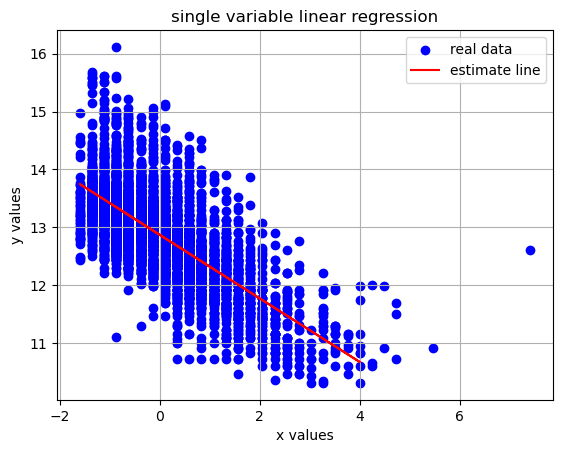

In [34]:
plt.scatter(X_train_single, y_train, color= 'blue')  # نمایش داده های اولیه با نقاط آبی روی نمودار
plt.plot(X_test_single, y_pred_single, color= 'red') #   رسم خط پیش بینی با داده های واقعی
# add lables to plot
plt.xlabel('x values')
plt.ylabel('y values')
plt.title('single variable linear regression')
plt.legend(['real data', 'estimate line', 'new data'])
plt.grid(True)
plt.show()

model intercept:12.86688646503608
model coef:[-0.05328331 -0.04326754 -0.00288945  0.09429793  0.26180622  0.00755429
  0.04518605 -0.45257227  0.01069109  0.17130965  0.01503975  0.04578001
 -0.01429928  0.0033351  -0.0195298   0.00174222 -0.1153092  -0.05740271
 -0.0419562  -0.09380226 -0.05484768 -0.11986598 -0.01615057 -0.14145428
 -0.12345558  0.00562558 -0.00610029 -0.03644208 -0.00749396 -0.06602414
 -0.03964348 -0.21161784 -0.03358921 -0.05743786]
Linear چندمتغیره             | MAE:       92,162 | RMSE:      171,756 | R²:   0.8655


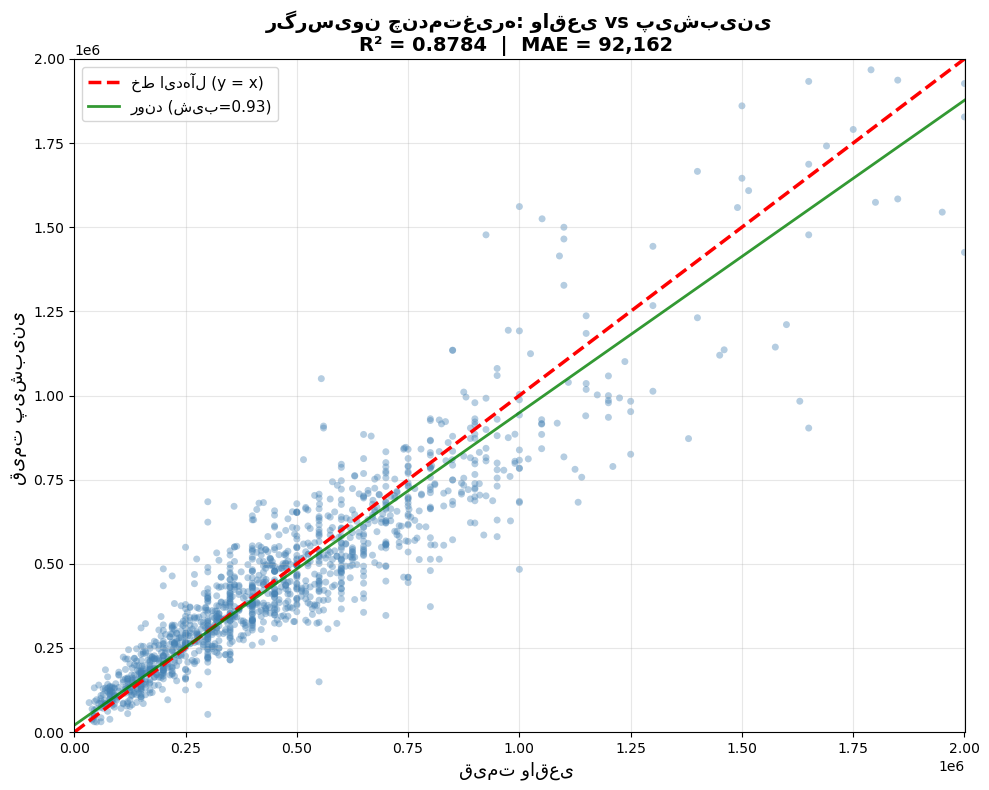

In [35]:
 # رگرسیون خطی چندمتغیره

# مدل
lr_multi = LinearRegression()
lr_multi.fit(X_train_scaled, y_train)
print(f"model intercept:{lr_multi.intercept_}") 
print(f"model coef:{lr_multi.coef_}")   
# پیش‌بینی
y_pred_multi = lr_multi.predict(X_test_scaled)

# ارزیابی
results.append(evaluate(y_test, y_pred_multi, "Linear چندمتغیره"))
# ========== نمودار ==========
y_true = np.expm1(y_test)
y_pred = np.expm1(y_pred_multi)
fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(y_true, y_pred, alpha=0.4, s=25, color="steelblue", edgecolors="none")
# خط ایده‌آل
max_val = max(y_true.max(), y_pred.max())
ax.plot([0, max_val], [0, max_val], "r--", linewidth=2.5, label="خط ایده‌آل (y = x)")
# خط رگرسیون (روند واقعی)
z = np.polyfit(y_true, y_pred, 1)
p = np.poly1d(z)
x_line = np.linspace(0, np.percentile(y_true, 99), 100)
ax.plot(x_line, p(x_line), "g-", linewidth=2, alpha=0.8, label=f"روند (شیب={z[0]:.2f})")
# محدود کردن محور
lim = np.percentile(y_true, 99)
ax.set_xlim(0, lim)
ax.set_ylim(0, lim)
# متریک‌ها در عنوان
r2 = r2_score(y_test, y_pred_multi)
mae = mean_absolute_error(y_true, y_pred)
ax.set_xlabel("قیمت واقعی ", fontsize=13)
ax.set_ylabel("قیمت پیش‌بینی ", fontsize=13)
ax.set_title(
    f"رگرسیون چندمتغیره: واقعی vs پیش‌بینی\n"
    f"R² = {r2:.4f}  |  MAE = {mae:,.0f} ",
    fontsize=14, fontweight="bold"
)
ax.legend(loc="upper left", fontsize=11)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [36]:
 # رگرسیون خطی چند جمله ای

alphas = np.logspace(-2, 4, 30)
kf = KFold(n_splits=5, shuffle=True, random_state=42)
# ۵ ویژگی برتر را برای این روش انتخاب می کنیم
top_features = ["car_age", "max_power", "engine", "torque", "km_driven"]
X_top = X[top_features].copy()

# Split
X_train_top, X_test_top, y_train_p, y_test_p = train_test_split(
    X_top, y_log, test_size=0.2, random_state=42
)
# ========== Pipeline برای هر مدل ==========
models = {
    "Poly2 + Ridge": Pipeline([
        ("poly", PolynomialFeatures(degree=2, include_bias=False)),
        ("scaler", StandardScaler()),
        ("model", RidgeCV(alphas=alphas, cv=5)),
    ]),
    "Poly2 + Lasso": Pipeline([
        ("poly", PolynomialFeatures(degree=2, include_bias=False)),
        ("scaler", StandardScaler()),
        ("model", LassoCV(alphas=alphas, cv=5, max_iter=10000)),
    ]),
    "Poly2 + ElasticNet": Pipeline([
        ("poly", PolynomialFeatures(degree=2, include_bias=False)),
        ("scaler", StandardScaler()),
        ("model", ElasticNetCV(alphas=alphas, l1_ratio=[0.1, 0.3, 0.5, 0.7, 0.9, 1.0],
                                cv=5, max_iter=10000)),
    ]),
}
# ========== آموزش و ارزیابی ==========
print("=" * 70)
print("Polynomial + Regularization")
print("=" * 70)
# results = []
coefs_dict = {}
for name, pipe in models.items():
    pipe.fit(X_train_top, y_train_p)
    y_pred_log = pipe.predict(X_test_top)

    y_true = np.expm1(y_test_p)
    y_pred = np.expm1(y_pred_log)

    r2 = r2_score(y_test_p, y_pred_log)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    results.append({"name": name, "r2": r2, "mae": mae, "rmse": rmse})
    # print(results)
    feature_names = pipe.named_steps["poly"].get_feature_names_out(top_features) 
    coefficients = pipe.named_steps["model"].coef_
    coefs_dict[name] = pd.DataFrame({
       "feature": feature_names,
       "coefficient": coefficients,
       "abs_coef": np.abs(coefficients),
    }).sort_values("abs_coef", ascending=False).reset_index(drop=True)

    # بهترین α
    best_alpha = pipe.named_steps["model"].alpha_
    best_l1 = getattr(pipe.named_steps["model"], "l1_ratio_", None)
    alpha_str = f"α={best_alpha:.4f}" + (f", ρ={best_l1:.2f}" if best_l1 else "")

    print(f"{name:22s} | R²: {r2:.4f} | MAE: {mae:>12,.0f} | {alpha_str}")

# ========== Cross-Validation ==========
print("\n" + "=" * 70)
print("Cross-Validation (۵-Fold)")
print("=" * 70)

for name, pipe in models.items():
    scores = cross_val_score(pipe, X_top, y_log, cv=kf, scoring="r2", n_jobs=-1)
    print(f"{name:22s} | R²: {scores.mean():.4f} ± {scores.std():.4f}")

Polynomial + Regularization
Poly2 + Ridge          | R²: 0.8356 | MAE:      105,760 | α=0.7279
Poly2 + Lasso          | R²: 0.8209 | MAE:      113,345 | α=0.0100
Poly2 + ElasticNet     | R²: 0.8322 | MAE:      107,461 | α=0.0100, ρ=0.10

Cross-Validation (۵-Fold)
Poly2 + Ridge          | R²: 0.8447 ± 0.0099
Poly2 + Lasso          | R²: 0.8308 ± 0.0092
Poly2 + ElasticNet     | R²: 0.8415 ± 0.0100


In [37]:
# جدول نهایی همه مدل ها

results_df = pd.DataFrame(results)
results_df = results_df[["name", "mae", "rmse", "r2"]].sort_values("r2", ascending=False)

print("=" * 80)
print(" جدول نهایی همه مدل‌ها")
print("=" * 80)
print(results_df.to_string(index=False))

 جدول نهایی همه مدل‌ها
                       name           mae          rmse       r2
           Linear چندمتغیره  92162.186760 171755.712269 0.865494
              Poly2 + Ridge 105759.758668 179408.315866 0.835568
         Poly2 + ElasticNet 107461.380487 187293.792761 0.832171
              Poly2 + Lasso 113344.612309 200317.127188 0.820855
Linear تک‌ متغیره (car_age) 194048.499422 411752.976319 0.226978


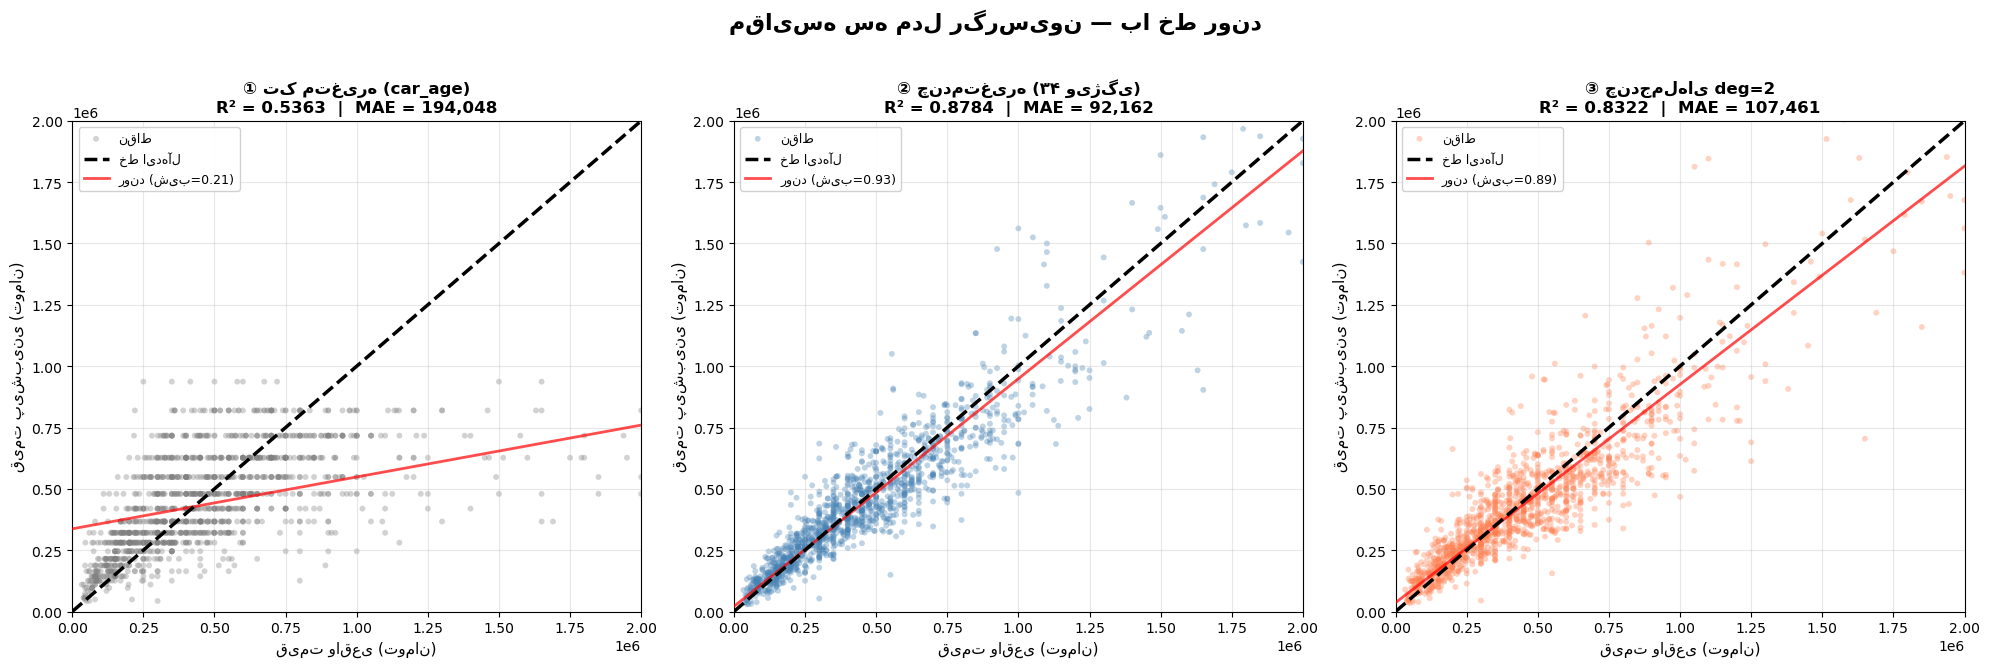

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6.5))


# برگرداندن به مقیاس اصلی (تومان)
y_true = np.expm1(y_test)
y_single = np.expm1(y_pred_single)
y_multi = np.expm1(y_pred_multi)
y_poly2 = np.expm1(y_pred_log)

# ========== متریک‌ها ==========
def get_metrics(y_t, y_p):
    return {
        "r2": r2_score(np.log1p(y_t), np.log1p(y_p)),
        "mae": mean_absolute_error(y_t, y_p),
        "rmse": np.sqrt(mean_squared_error(y_t, y_p))
    }

m_single = get_metrics(y_true, y_single)
m_multi = get_metrics(y_true, y_multi)
m_poly2 = get_metrics(y_true, y_poly2)

models = [
    ("① تک‌ متغیره (car_age)", y_single, "gray", m_single),
    ("② چندمتغیره (۳۴ ویژگی)", y_multi, "steelblue", m_multi),
    ("③ چندجمله‌ای deg=2", y_poly2, "coral", m_poly2),
]

for ax, (title, y_pred, color, metrics) in zip(axes, models):
    ax.scatter(y_true, y_pred, alpha=0.35, s=18, color=color, edgecolors="none", label="نقاط")

    # خط ایده‌آل
    max_val = max(y_true.max(), y_pred.max())
    ax.plot([0, max_val], [0, max_val], "k--", linewidth=2.5, label="خط ایده‌آل", zorder=5)

    # خط رگرسیون (روند واقعی)
    z = np.polyfit(y_true, y_pred, 1)
    p = np.poly1d(z)
    x_line = np.linspace(0, np.percentile(y_true, 99), 100)
    ax.plot(x_line, p(x_line), "r-", linewidth=2, alpha=0.7, label=f"روند (شیب={z[0]:.2f})", zorder=4)

    lim = np.percentile(y_true, 99)
    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)

    ax.set_xlabel("قیمت واقعی (تومان)", fontsize=11)
    ax.set_ylabel("قیمت پیش‌بینی (تومان)", fontsize=11)
    ax.set_title(
        f"{title}\n"
        f"R² = {metrics['r2']:.4f}  |  MAE = {metrics['mae']:,.0f}",
        fontsize=12, fontweight="bold"
    )
    ax.legend(loc="upper left", fontsize=9, framealpha=0.9)
    ax.grid(alpha=0.3)

plt.suptitle("مقایسه سه مدل رگرسیون — با خط روند",
             fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()